# EDA

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv(
    "../data/data_gabungan/airguard_harian_kualitas_udara_jawa.csv"
)

df["tanggal"] = pd.to_datetime(df["tanggal"])

print("Ukuran data:", df.shape)
print("Periode:", df["tanggal"].min().date(), "sampai", df["tanggal"].max().date())
print("Jumlah kab/kota:", df["kode_kabkota"].nunique())

display(df.head())

Ukuran data: (183379, 16)
Periode: 2022-08-04 sampai 2026-10-22
Jumlah kab/kota: 119


,kode_kabkota,nama_kabkota,provinsi,tipe,latitude,longitude,elevasi_m,luas_km2,penduduk,tanggal,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone
0,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-04,39.317647,25.705882,523.705882,5.552941,13.035294,136.941176
1,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-05,15.683333,9.258333,164.791667,1.591667,2.995833,83.833333
2,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-06,33.704167,21.075000,455.916667,5.162500,8.304167,148.583333
3,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-07,43.504167,27.645833,360.375000,3.600000,5.375000,146.458333
4,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-08,54.600000,36.504167,776.375000,22.366667,16.437500,108.708333


In [39]:
print("Tipe data:")
display(df.dtypes)

print("Missing value:")
display(df.isna().sum().sort_values(ascending=False))

print(
    "Duplikat kab/kota-tanggal:",
    df.duplicated(["kode_kabkota", "tanggal"]).sum()
)


Tipe data:


kode_kabkota               float64
nama_kabkota                object
provinsi                    object
tipe                        object
latitude                   float64
longitude                  float64
elevasi_m                  float64
luas_km2                   float64
penduduk                   float64
tanggal             datetime64[ns]
pm10                       float64
pm2_5                      float64
carbon_monoxide            float64
nitrogen_dioxide           float64
sulphur_dioxide            float64
ozone                      float64
dtype: object

Missing value:


kode_kabkota        0
nama_kabkota        0
provinsi            0
tipe                0
latitude            0
longitude           0
elevasi_m           0
luas_km2            0
penduduk            0
tanggal             0
pm10                0
pm2_5               0
carbon_monoxide     0
nitrogen_dioxide    0
sulphur_dioxide     0
ozone               0
dtype: int64

Duplikat kab/kota-tanggal: 0


In [40]:
coverage = (
    df.groupby(["kode_kabkota", "nama_kabkota"])
      .agg(
          jumlah_hari=("tanggal", "nunique"),
          tanggal_awal=("tanggal", "min"),
          tanggal_akhir=("tanggal", "max")
      )
      .reset_index()
)

display(coverage["jumlah_hari"].value_counts())
display(coverage.head())
display(coverage.tail())

jumlah_hari
1541    119
Name: count, dtype: int64

,kode_kabkota,nama_kabkota,jumlah_hari,tanggal_awal,tanggal_akhir
0,31.01,Kabupaten Administrasi Kepulauan Seribu,1541,2022-08-04,2026-10-22
1,31.71,Kota Administrasi Jakarta Pusat,1541,2022-08-04,2026-10-22
2,31.72,Kota Administrasi Jakarta Utara,1541,2022-08-04,2026-10-22
3,31.73,Kota Administrasi Jakarta Barat,1541,2022-08-04,2026-10-22
4,31.74,Kota Administrasi Jakarta Selatan,1541,2022-08-04,2026-10-22


,kode_kabkota,nama_kabkota,jumlah_hari,tanggal_awal,tanggal_akhir
114,36.04,Kabupaten Serang,1541,2022-08-04,2026-10-22
115,36.71,Kota Tangerang,1541,2022-08-04,2026-10-22
116,36.72,Kota Cilegon,1541,2022-08-04,2026-10-22
117,36.73,Kota Serang,1541,2022-08-04,2026-10-22
118,36.74,Kota Tangerang Selatan,1541,2022-08-04,2026-10-22


In [41]:
kolom_polutan = [
    "pm2_5",
    "pm10",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone"
]

df[kolom_polutan].describe().T


,count,mean,std,min,25%,50%,75%,max
pm2_5,183379.0,37.041132,22.622870,0.616667,19.308333,31.716667,49.404167,159.679167
pm10,183379.0,44.826694,24.688009,0.887500,25.841667,39.362500,58.408333,196.954167
carbon_monoxide,183379.0,680.726864,571.991789,59.125000,338.083333,508.791667,786.041667,6181.041667
nitrogen_dioxide,183379.0,19.920032,18.395207,0.000000,7.816667,14.112500,24.962500,159.008333
sulphur_dioxide,183379.0,13.950150,14.359481,0.000000,3.691667,9.079167,19.279167,162.495833
ozone,183379.0,66.393174,27.576706,8.958333,46.250000,62.250000,82.666667,228.583333


In [42]:
df["tanggal"] = pd.to_datetime(df["tanggal"])

coverage = (
    df.groupby(["kode_kabkota", "nama_kabkota"])
      .agg(
          jumlah_hari=("tanggal", "nunique"),
          tanggal_awal=("tanggal", "min"),
          tanggal_akhir=("tanggal", "max")
      )
      .reset_index()
)

display(coverage["jumlah_hari"].value_counts().sort_index())
display(coverage.head())

jumlah_hari
1541    119
Name: count, dtype: int64

,kode_kabkota,nama_kabkota,jumlah_hari,tanggal_awal,tanggal_akhir
0,31.01,Kabupaten Administrasi Kepulauan Seribu,1541,2022-08-04,2026-10-22
1,31.71,Kota Administrasi Jakarta Pusat,1541,2022-08-04,2026-10-22
2,31.72,Kota Administrasi Jakarta Utara,1541,2022-08-04,2026-10-22
3,31.73,Kota Administrasi Jakarta Barat,1541,2022-08-04,2026-10-22
4,31.74,Kota Administrasi Jakarta Selatan,1541,2022-08-04,2026-10-22


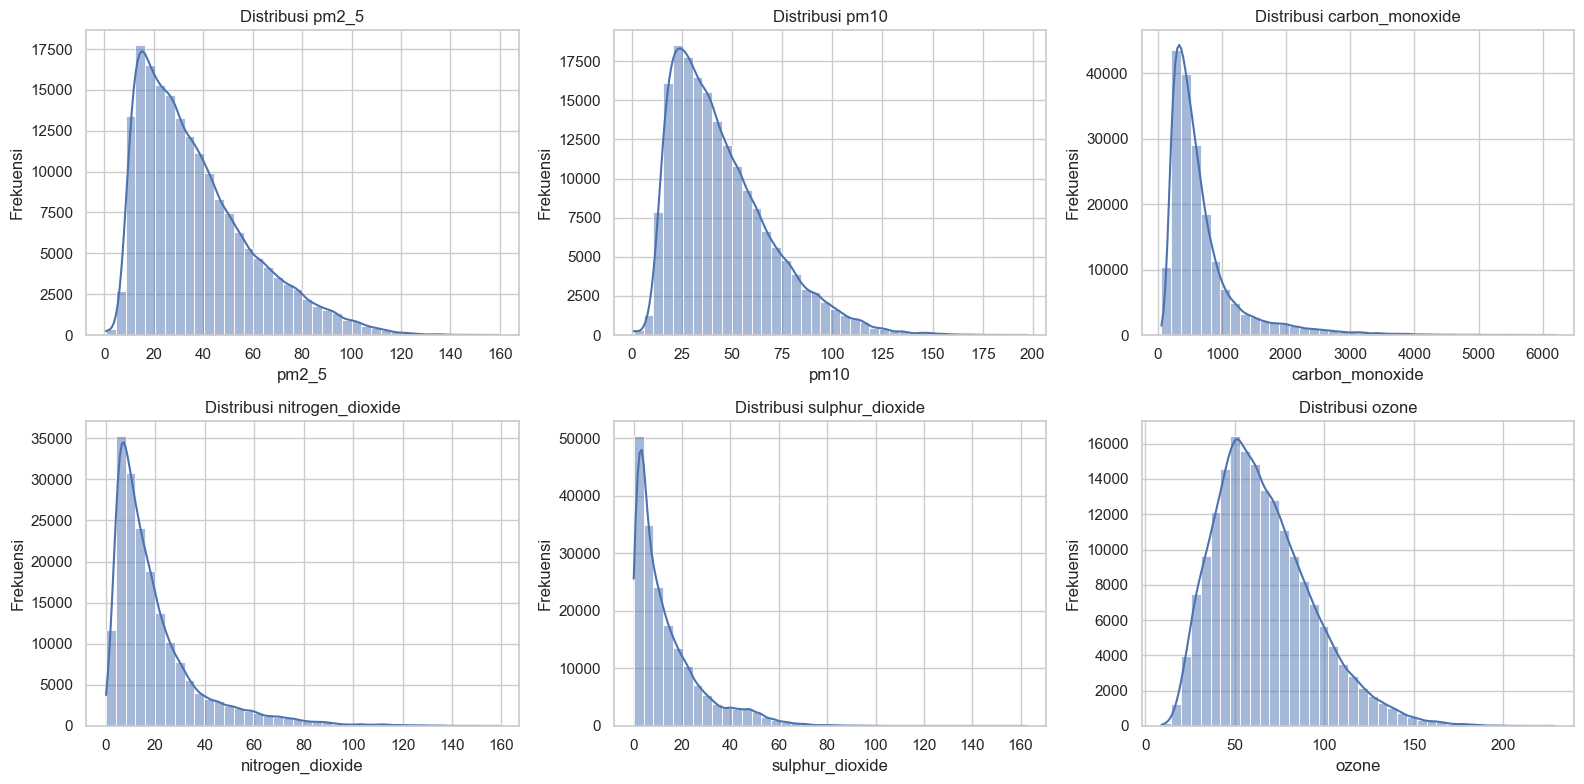

In [43]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, kolom in zip(axes.flatten(), kolom_polutan):
    sns.histplot(df[kolom], bins=40, kde=True, ax=ax)
    ax.set_title(f"Distribusi {kolom}")
    ax.set_xlabel(kolom)
    ax.set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

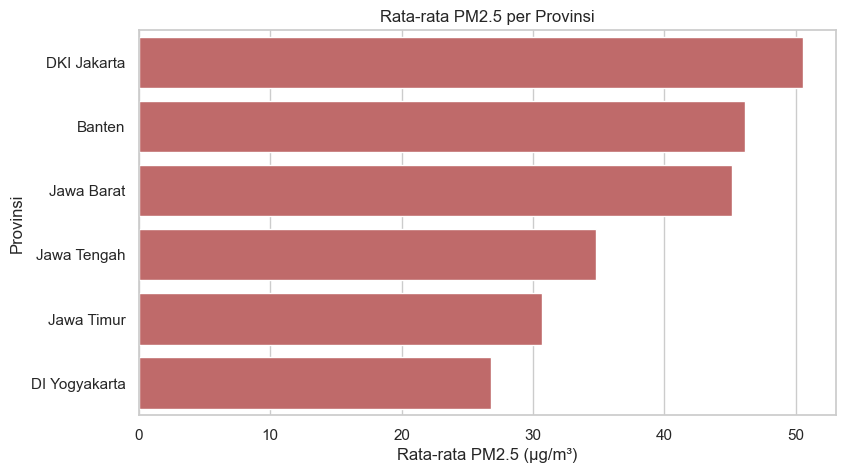

In [44]:
rata_provinsi = (
    df.groupby("provinsi", as_index=False)["pm2_5"]
      .mean()
      .sort_values("pm2_5", ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=rata_provinsi,
    x="pm2_5",
    y="provinsi",
    color="indianred"
)

plt.title("Rata-rata PM2.5 per Provinsi")
plt.xlabel("Rata-rata PM2.5 (µg/m³)")
plt.ylabel("Provinsi")
plt.show()

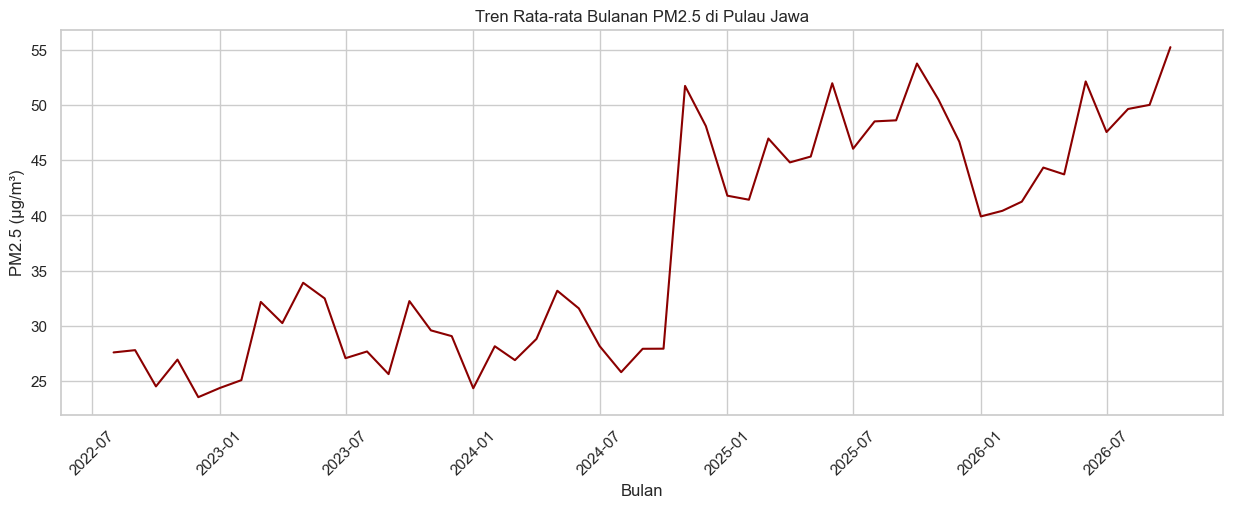

In [45]:
df["bulan"] = df["tanggal"].dt.to_period("M").dt.to_timestamp()

tren_bulanan = (
    df.groupby("bulan", as_index=False)["pm2_5"]
      .mean()
)

plt.figure(figsize=(15, 5))

sns.lineplot(
    data=tren_bulanan,
    x="bulan",
    y="pm2_5",
    color="darkred"
)

plt.title("Tren Rata-rata Bulanan PM2.5 di Pulau Jawa")
plt.xlabel("Bulan")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation=45)
plt.show()


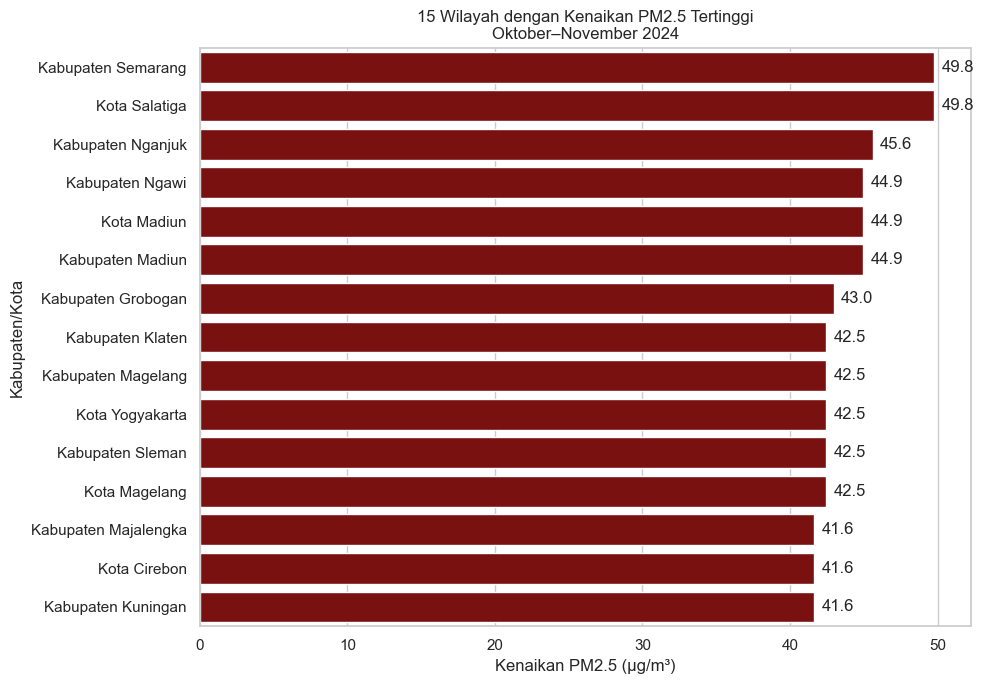

In [46]:
plt.figure(figsize=(10, 7))

perubahan_tertinggi = (
    perubahan
    .sort_values("perubahan_absolut", ascending=False)
    .head(15)
)

sns.barplot(
    data=perubahan_tertinggi,
    x="perubahan_absolut",
    y=perubahan_tertinggi.index,
    color="darkred"
)

for bar in plt.gca().patches:
    nilai = bar.get_width()
    plt.text(
        nilai + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{nilai:.1f}",
        va="center"
    )

plt.title("15 Wilayah dengan Kenaikan PM2.5 Tertinggi\nOktober–November 2024")
plt.xlabel("Kenaikan PM2.5 (µg/m³)")
plt.ylabel("Kabupaten/Kota")
plt.tight_layout()
plt.show()

In [72]:
# Pastikan tanggal bertipe datetime
df["tanggal"] = pd.to_datetime(df["tanggal"])

# Membuat bulan dalam format tanggal awal bulan
df["bulan"] = (
    df["tanggal"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Rata-rata PM2.5 per kabupaten/kota per bulan
monthly_city = (
    df.groupby(["nama_kabkota", "bulan"], as_index=False)["pm2_5"]
      .mean()
      .rename(columns={"pm2_5": "rata_rata_pm2_5"})
)

# Ubah format menjadi baris = kabupaten/kota, kolom = bulan
pivot_city = monthly_city.pivot(
    index="nama_kabkota",
    columns="bulan",
    values="rata_rata_pm2_5"
)

# Ambil Oktober dan November 2024
oktober = pivot_city[pd.Timestamp("2024-10-01")]
november = pivot_city[pd.Timestamp("2024-11-01")]

# Gabungkan data
perubahan = pd.DataFrame({
    "pm25_oktober": oktober,
    "pm25_november": november
}).dropna()

# Hitung perubahan
perubahan["perubahan_absolut"] = (
    perubahan["pm25_november"]
    - perubahan["pm25_oktober"]
)

perubahan["perubahan_persen"] = (
    perubahan["perubahan_absolut"]
    / perubahan["pm25_oktober"]
    * 100
)

# Urutkan berdasarkan kenaikan absolut terbesar
perubahan = perubahan.sort_values(
    "perubahan_absolut",
    ascending=False
)

display(perubahan.head(15).round(2))


,pm25_oktober,pm25_november,perubahan_absolut,perubahan_persen
nama_kabkota,,,,
Kabupaten Semarang,30.29,80.07,49.78,164.35
Kota Salatiga,30.29,80.07,49.78,164.35
Kabupaten Nganjuk,19.20,64.82,45.62,237.58
Kabupaten Ngawi,17.57,62.51,44.94,255.79
Kota Madiun,17.57,62.51,44.94,255.79
Kabupaten Madiun,17.57,62.51,44.94,255.79
Kabupaten Grobogan,26.25,69.22,42.97,163.66
Kabupaten Klaten,17.05,59.51,42.45,248.93
Kabupaten Magelang,17.05,59.51,42.45,248.93


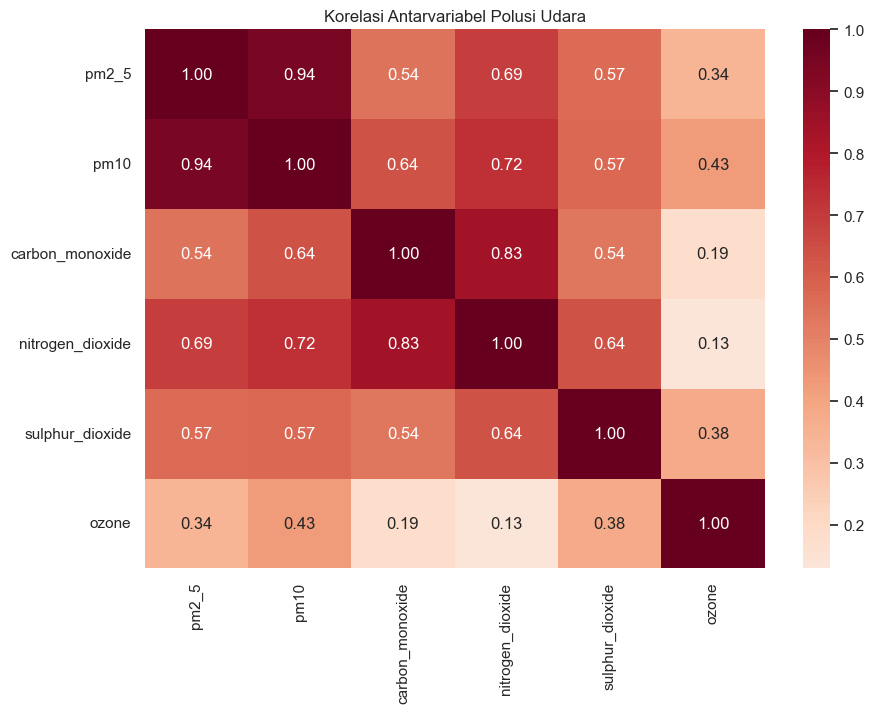

In [47]:
plt.figure(figsize=(10, 7))

corr = df[kolom_polutan].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="RdBu_r",
    center=0,
    fmt=".2f"
)

plt.title("Korelasi Antarvariabel Polusi Udara")
plt.show()


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_37104\1680681288.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


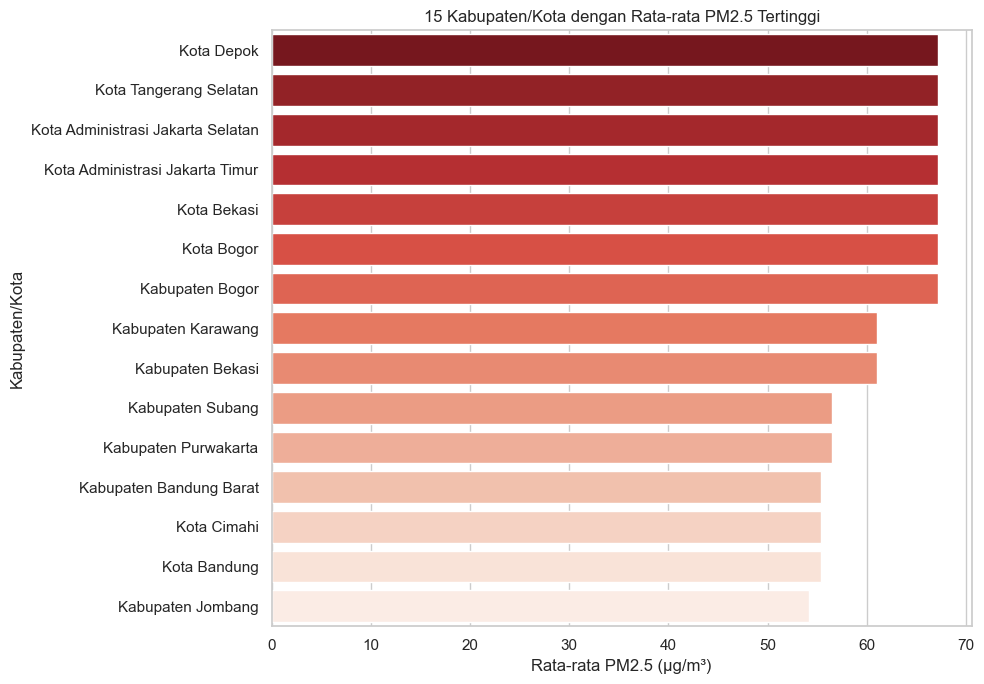

In [48]:
ranking_kota = (
    df.groupby("nama_kabkota", as_index=False)["pm2_5"]
      .mean()
      .sort_values("pm2_5", ascending=False)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=ranking_kota.head(15),
    x="pm2_5",
    y="nama_kabkota",
    palette="Reds_r"
)

plt.title("15 Kabupaten/Kota dengan Rata-rata PM2.5 Tertinggi")
plt.xlabel("Rata-rata PM2.5 (µg/m³)")
plt.ylabel("Kabupaten/Kota")
plt.tight_layout()
plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_37104\3179043077.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


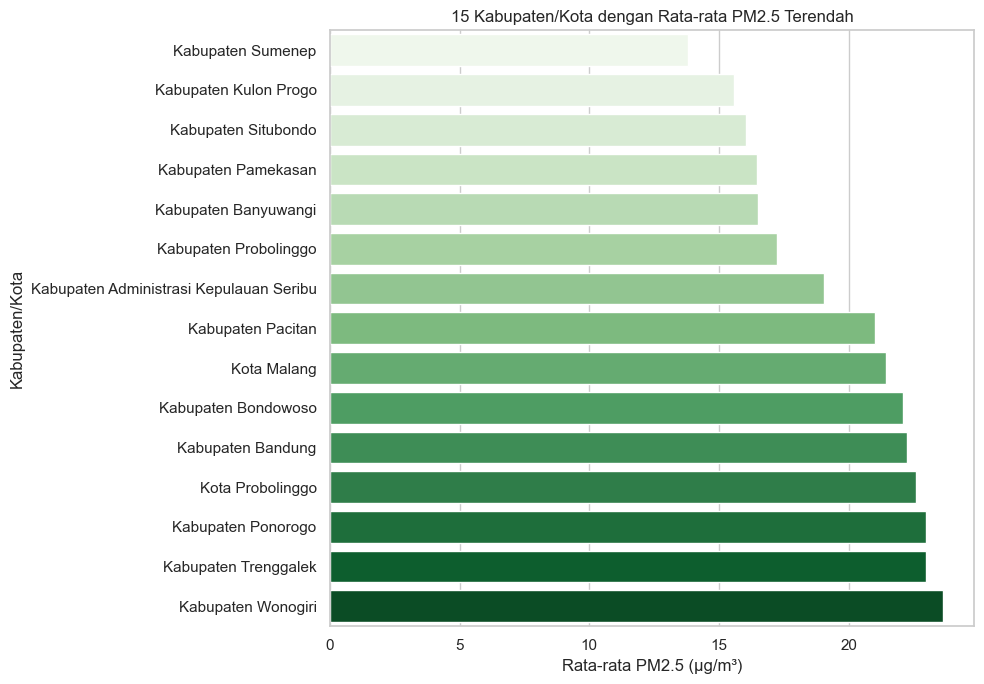

In [49]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=ranking_kota.tail(15).sort_values("pm2_5"),
    x="pm2_5",
    y="nama_kabkota",
    palette="Greens"
)

plt.title("15 Kabupaten/Kota dengan Rata-rata PM2.5 Terendah")
plt.xlabel("Rata-rata PM2.5 (µg/m³)")
plt.ylabel("Kabupaten/Kota")
plt.tight_layout()
plt.show()


In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Pastikan format data benar
df = df.copy()
df["tanggal"] = pd.to_datetime(df["tanggal"])
df = df.sort_values(["nama_kabkota", "tanggal"]).reset_index(drop=True)

# Ambang operasional risiko
BATAS_BAIK = 15
BATAS_TINGGI = 55

def kategori_risiko(pm25):
    if pm25 <= BATAS_BAIK:
        return "Baik"
    elif pm25 <= BATAS_TINGGI:
        return "Sedang"
    return "Tidak Sehat"

df["kategori_risiko"] = df["pm2_5"].apply(kategori_risiko)

,Jumlah Observasi,Persentase (%)
kategori_risiko,,
Baik,27514,15.00
Sedang,119849,65.36
Tidak Sehat,36016,19.64


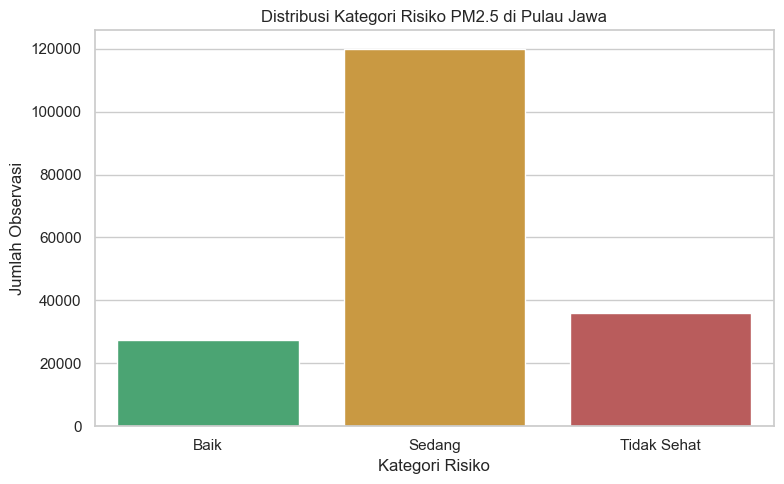

In [75]:
risiko = (
    df["kategori_risiko"]
    .value_counts()
    .reindex(["Baik", "Sedang", "Tidak Sehat"])
)

risiko_persen = (risiko / risiko.sum() * 100).round(2)

tabel_risiko = pd.DataFrame({
    "Jumlah Observasi": risiko,
    "Persentase (%)": risiko_persen
})

display(tabel_risiko)

plt.figure(figsize=(8, 5))

warna = {
    "Baik": "#3CB371",
    "Sedang": "#E0A02B",
    "Tidak Sehat": "#C94C4C"
}

sns.barplot(
    x=tabel_risiko.index,
    y=tabel_risiko["Jumlah Observasi"],
    hue=tabel_risiko.index,
    palette=warna,
    legend=False
)

plt.title("Distribusi Kategori Risiko PM2.5 di Pulau Jawa")
plt.xlabel("Kategori Risiko")
plt.ylabel("Jumlah Observasi")
plt.tight_layout()
plt.show()


In [76]:
provinsi_risiko = (
    df.groupby("provinsi")
    .agg(
        rata_rata_pm25=("pm2_5", "mean"),
        median_pm25=("pm2_5", "median"),
        maksimum_pm25=("pm2_5", "max"),
        jumlah_hari=("pm2_5", "size"),
        jumlah_hari_tinggi=("pm2_5", lambda x: (x > BATAS_TINGGI).sum())
    )
    .reset_index()
)

provinsi_risiko["persentase_hari_tinggi"] = (
    provinsi_risiko["jumlah_hari_tinggi"]
    / provinsi_risiko["jumlah_hari"]
    * 100
)

provinsi_risiko = provinsi_risiko.sort_values(
    "persentase_hari_tinggi",
    ascending=False
)

display(provinsi_risiko.round(2))


,provinsi,rata_rata_pm25,median_pm25,maksimum_pm25,jumlah_hari,jumlah_hari_tinggi,persentase_hari_tinggi
2,DKI Jakarta,50.54,49.28,150.09,9246,3869,41.85
0,Banten,46.12,44.38,154.93,12328,4272,34.65
3,Jawa Barat,45.14,41.09,154.62,41607,13292,31.95
4,Jawa Tengah,34.79,30.04,143.02,53935,7470,13.85
5,Jawa Timur,30.67,26.33,159.68,58558,6468,11.05
1,DI Yogyakarta,26.78,20.21,126.24,7705,645,8.37


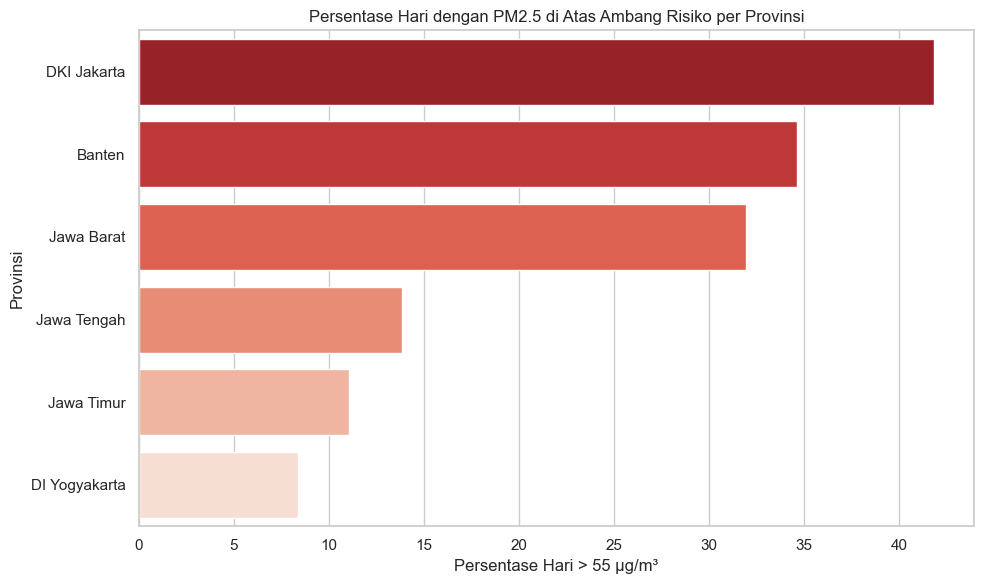

In [77]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=provinsi_risiko,
    y="provinsi",
    x="persentase_hari_tinggi",
    hue="provinsi",
    palette="Reds_r",
    legend=False
)

plt.title("Persentase Hari dengan PM2.5 di Atas Ambang Risiko per Provinsi")
plt.xlabel("Persentase Hari > 55 µg/m³")
plt.ylabel("Provinsi")
plt.tight_layout()
plt.show()


In [82]:
df["tahun"] = df["tanggal"].dt.year

tren_tahunan = (
    df.groupby("tahun")
    .agg(
        rata_rata_pm25=("pm2_5", "mean"),
        median_pm25=("pm2_5", "median"),
        maksimum_pm25=("pm2_5", "max"),
        persentase_hari_tinggi=("pm2_5", lambda x: (x > BATAS_TINGGI).mean() * 100),
        jumlah_observasi=("pm2_5", "size")
    )
    .reset_index()
)

display(tren_tahunan.round(2))


,tahun,rata_rata_pm25,median_pm25,maksimum_pm25,persentase_hari_tinggi,jumlah_observasi
0,2022,26.05,21.21,112.23,7.09,17850
1,2023,29.17,24.50,136.59,8.77,43435
2,2024,31.88,26.00,159.68,13.20,43554
3,2025,47.21,43.55,150.25,33.27,43435
4,2026,46.18,41.90,154.93,30.59,35105


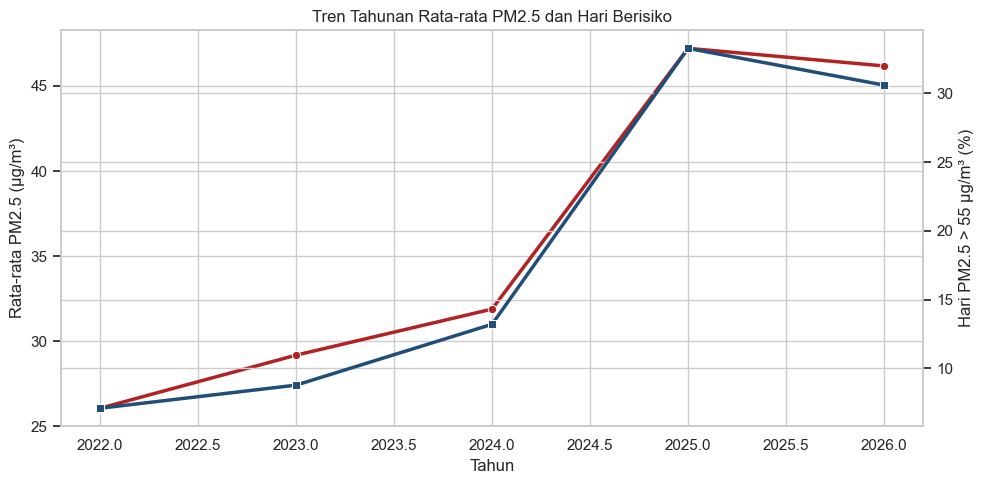

In [83]:
fig, ax1 = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=tren_tahunan,
    x="tahun",
    y="rata_rata_pm25",
    marker="o",
    linewidth=2.5,
    color="#B22222",
    ax=ax1
)

ax1.set_xlabel("Tahun")
ax1.set_ylabel("Rata-rata PM2.5 (µg/m³)")
ax1.set_title("Tren Tahunan Rata-rata PM2.5 dan Hari Berisiko")

ax2 = ax1.twinx()

sns.lineplot(
    data=tren_tahunan,
    x="tahun",
    y="persentase_hari_tinggi",
    marker="s",
    linewidth=2.5,
    color="#1F4E79",
    ax=ax2
)

ax2.set_ylabel("Hari PM2.5 > 55 µg/m³ (%)")

plt.tight_layout()
plt.show()

In [84]:
df_episode = df.copy()

df_episode["is_high"] = df_episode["pm2_5"] > BATAS_TINGGI

df_episode["perubahan_status"] = (
    df_episode.groupby("nama_kabkota")["is_high"]
    .transform(lambda x: x.ne(x.shift()).cumsum())
)

episode = (
    df_episode[df_episode["is_high"]]
    .groupby(["nama_kabkota", "provinsi", "perubahan_status"])
    .agg(
        tanggal_mulai=("tanggal", "min"),
        tanggal_selesai=("tanggal", "max"),
        durasi_hari=("tanggal", "size"),
        rata_rata_pm25=("pm2_5", "mean"),
        maksimum_pm25=("pm2_5", "max")
    )
    .reset_index()
)

episode = episode[episode["durasi_hari"] >= 3]

episode = episode.sort_values(
    ["durasi_hari", "rata_rata_pm25"],
    ascending=False
)

display(episode.head(20).round(2))

,nama_kabkota,provinsi,perubahan_status,tanggal_mulai,tanggal_selesai,durasi_hari,rata_rata_pm25,maksimum_pm25
593,Kabupaten Bekasi,Jawa Barat,242,2026-05-27,2026-10-22,149,93.56,142.94
2184,Kabupaten Karawang,Jawa Barat,242,2026-05-27,2026-10-22,149,93.56,142.94
760,Kabupaten Bogor,Jawa Barat,193,2025-06-21,2025-11-04,137,91.71,150.09
6387,Kota Administrasi Jakarta Selatan,DKI Jakarta,193,2025-06-21,2025-11-04,137,91.71,150.09
6508,Kota Administrasi Jakarta Timur,DKI Jakarta,193,2025-06-21,2025-11-04,137,91.71,150.09
7030,Kota Bekasi,Jawa Barat,193,2025-06-21,2025-11-04,137,91.71,150.09
7193,Kota Bogor,Jawa Barat,193,2025-06-21,2025-11-04,137,91.71,150.09
7615,Kota Depok,Jawa Barat,193,2025-06-21,2025-11-04,137,91.71,150.09
8871,Kota Tangerang Selatan,Banten,193,2025-06-21,2025-11-04,137,91.71,150.09
575,Kabupaten Bekasi,Jawa Barat,206,2025-07-08,2025-11-11,127,89.26,150.25


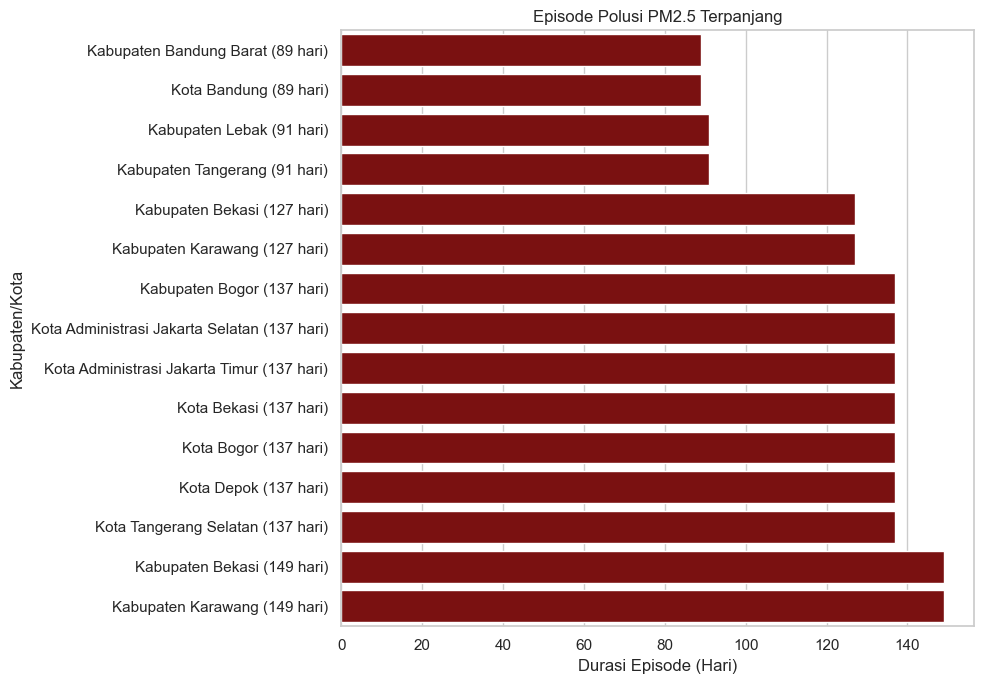

In [85]:
plt.figure(figsize=(10, 7))

episode_top = episode.head(15).copy()

episode_top["label"] = (
    episode_top["nama_kabkota"]
    + " ("
    + episode_top["durasi_hari"].astype(str)
    + " hari)"
)

sns.barplot(
    data=episode_top.sort_values("durasi_hari"),
    x="durasi_hari",
    y="label",
    color="#8B0000"
)

plt.title("Episode Polusi PM2.5 Terpanjang")
plt.xlabel("Durasi Episode (Hari)")
plt.ylabel("Kabupaten/Kota")
plt.tight_layout()
plt.show()


# Preprocessing

In [53]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/data_gabungan/airguard_harian_kualitas_udara_jawa.csv",
    dtype={"kode_kabkota": "string"}
)

df["tanggal"] = pd.to_datetime(df["tanggal"])

df = df.sort_values(
    ["kode_kabkota", "tanggal"]
).reset_index(drop=True)

print("Ukuran data:", df.shape)
print("Jumlah kab/kota:", df["kode_kabkota"].nunique())
print("Periode:", df["tanggal"].min().date(), "sampai", df["tanggal"].max().date())

Ukuran data: (183379, 16)
Jumlah kab/kota: 119
Periode: 2022-08-04 sampai 2026-10-22


In [61]:
coverage = (
    df.groupby("kode_kabkota")
      .agg(
          jumlah_hari=("tanggal", "nunique"),
          tanggal_awal=("tanggal", "min"),
          tanggal_akhir=("tanggal", "max")
      )
      .reset_index()
)

print("Distribusi jumlah hari:")
print(coverage["jumlah_hari"].value_counts())

assert coverage["jumlah_hari"].nunique() == 1
assert df.duplicated(["kode_kabkota", "tanggal"]).sum() == 0

print("Validasi tanggal berhasil.")

Distribusi jumlah hari:
jumlah_hari
1541    119
Name: count, dtype: int64
Validasi tanggal berhasil.


In [62]:
# Feature Engineerin Waktu

df_pre = df.copy()

df_pre["tahun"] = df_pre["tanggal"].dt.year
df_pre["bulan"] = df_pre["tanggal"].dt.month
df_pre["hari_dalam_minggu"] = df_pre["tanggal"].dt.dayofweek
df_pre["hari_dalam_tahun"] = df_pre["tanggal"].dt.dayofyear

# Representasi siklus waktu
df_pre["bulan_sin"] = np.sin(
    2 * np.pi * df_pre["bulan"] / 12
)

df_pre["bulan_cos"] = np.cos(
    2 * np.pi * df_pre["bulan"] / 12
)

df_pre["hari_tahun_sin"] = np.sin(
    2 * np.pi * df_pre["hari_dalam_tahun"] / 365.25
)

df_pre["hari_tahun_cos"] = np.cos(
    2 * np.pi * df_pre["hari_dalam_tahun"] / 365.25
)


In [63]:
# Membuat fitur rolling average

for window in [3, 7, 14]:
    df_pre[f"pm2_5_rolling_{window}"] = (
        df_pre
        .groupby("kode_kabkota")["pm2_5"]
        .transform(
            lambda x: x.rolling(
                window=window,
                min_periods=window
            ).mean()
        )
    )

In [64]:
# Membuat target PM2.5 (Fitur tanggal t → memprediksi PM2.5 tanggal t+1)

df_pre["target_pm2_5"] = (
    df_pre
    .groupby("kode_kabkota")["pm2_5"]
    .shift(-1)
)

In [66]:
# Pastikan data sudah diurutkan
df_pre = df.copy()

df_pre["tanggal"] = pd.to_datetime(df_pre["tanggal"])

df_pre = (
    df_pre
    .sort_values(["kode_kabkota", "tanggal"])
    .reset_index(drop=True)
)

# Lag PM2.5 per kabupaten/kota
for lag in [1, 2, 3, 7, 14]:
    df_pre[f"pm2_5_lag_{lag}"] = (
        df_pre
        .groupby("kode_kabkota")["pm2_5"]
        .shift(lag)
    )

# Rolling average PM2.5 per kabupaten/kota
for window in [3, 7, 14]:
    df_pre[f"pm2_5_rolling_{window}"] = (
        df_pre
        .groupby("kode_kabkota")["pm2_5"]
        .transform(
            lambda x: x.rolling(
                window=window,
                min_periods=window
            ).mean()
        )
    )

# Target PM2.5 hari berikutnya
df_pre["target_pm2_5"] = (
    df_pre
    .groupby("kode_kabkota")["pm2_5"]
    .shift(-1)
)

fitur_lag_rolling = [
    "pm2_5_lag_1",
    "pm2_5_lag_2",
    "pm2_5_lag_3",
    "pm2_5_lag_7",
    "pm2_5_lag_14",
    "pm2_5_rolling_3",
    "pm2_5_rolling_7",
    "pm2_5_rolling_14"
]

df_preprocessed = (
    df_pre
    .dropna(
        subset=fitur_lag_rolling + ["target_pm2_5"]
    )
    .reset_index(drop=True)
)

print("Ukuran awal:", df.shape)
print("Ukuran setelah preprocessing:", df_preprocessed.shape)
print("Missing value:", df_preprocessed.isna().sum().sum())


Ukuran awal: (183379, 16)
Ukuran setelah preprocessing: (181594, 25)
Missing value: 0


In [67]:
# Menghapus baris dengan fitur tidak lengkap

fitur_lag_rolling = [
    "pm2_5_lag_1",
    "pm2_5_lag_2",
    "pm2_5_lag_3",
    "pm2_5_lag_7",
    "pm2_5_lag_14",
    "pm2_5_rolling_3",
    "pm2_5_rolling_7",
    "pm2_5_rolling_14"
]

df_preprocessed = df_pre.dropna(
    subset=fitur_lag_rolling + ["target_pm2_5"]
).reset_index(drop=True)

print("Data awal       :", df.shape)
print("Data setelah pre:", df_preprocessed.shape)
print("Missing value   :", df_preprocessed.isna().sum().sum())

Data awal       : (183379, 16)
Data setelah pre: (181594, 25)
Missing value   : 0


In [68]:
# Membuat kategori risiko target

def label_status_risiko(nilai):
    if pd.isna(nilai):
        return np.nan
    elif nilai <= 15:
        return "Baik (Aman)"
    elif nilai <= 55:
        return "Sedang (Waspada)"
    else:
        return "Tidak Sehat (Bahaya)"


df_preprocessed["kategori_target_pm2_5"] = (
    df_preprocessed["target_pm2_5"]
    .apply(label_status_risiko)
)

display(
    df_preprocessed["kategori_target_pm2_5"]
    .value_counts()
)


kategori_target_pm2_5
Sedang (Waspada)        118774
Tidak Sehat (Bahaya)     35858
Baik (Aman)              26962
Name: count, dtype: int64

In [69]:
output_path = (
    "../data/data_gabungan/airguard_preprocessed.csv"
)

df_preprocessed.to_csv(
    output_path,
    index=False
)

print("File berhasil disimpan di:", output_path)

File berhasil disimpan di: ../data/data_gabungan/airguard_preprocessed.csv
